In [1]:
!pip -q install transformers scikit-learn psutil

In [2]:
import ast, glob, gzip, json, math, os, random, re, time, unicodedata, gc
from array import array
from collections import Counter, defaultdict
from types import SimpleNamespace

import numpy as np
import pandas as pd
import psutil
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, RandomSampler, WeightedRandomSampler
from transformers import AutoModel, AutoTokenizer, get_linear_schedule_with_warmup
from sklearn.metrics import average_precision_score, f1_score, precision_score, recall_score


def mem(tag=""):
    vm = psutil.virtual_memory()
    print(f"[RAM {tag}] used {vm.used / 2**30:.1f} / {vm.total / 2**30:.1f} GB")


print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE (switch runtime to GPU!)")
mem("start")

GPU: Tesla T4
[RAM start] used 1.5 / 31.3 GB


In [3]:
PROJ = "/kaggle/working/cs_predict"
os.makedirs(PROJ, exist_ok=True)

In [4]:
CFG = SimpleNamespace(
    raw_dir="/kaggle/input/datasets/sanidhya1904/switchlingua",   # folder with the SwitchLingua CSVs
    data_dir=f"{PROJ}/data",                         # compressed train/dev/test files
    run_dir=f"{PROJ}/runs/mbert",                    # small outputs: best model, tokenizer, results, logs
    ckpt_dir="/tmp/ckpt",                        # resume checkpoint on Colab's local disk (not your Drive)
    model_name="bert-base-multilingual-cased",
    max_rows_per_pair=20000,                         # None = all rows
    min_score=None,
    max_len=128,
    batch_size=32,
    epochs=2,
    lr=3e-5,
    warmup=0.1,
    lam_sw=1.0,
    lam_dur=1.0,
    sw_pos_weight=2.0,
    balance_pairs=False,
    extend_vocab=True,
    save_every=1000,                                 # steps between resume checkpoints
    seed=15,
)

In [5]:
PAIRS = {
    "yue-en": {"cantonese", "yue"},
    "zh-en": {"chinese", "mandarin", "zh"},
    "ja-en": {"japanese", "ja"},
    "ko-en": {"korean", "ko"},
    "ru-en": {"russian", "ru"},
    "ar-en": {"arabic", "ar"},
}
DUR_BINS = [(1, 2, 0), (3, 6, 1), (7, 10**9, 2)]
DUR_NAMES = ["small(1-2)", "medium(3-6)", "large(7+)"]
SPEAKER_RE = re.compile(r"^\s*(?:speaker|person|user)?\s*[A-Z0-9]{1,2}\s*[:：]\s*", re.I)


def char_class(ch):
    cat = unicodedata.category(ch)
    if cat.startswith("Z") or ch.isspace():
        return "S"
    if cat == "Nd":
        return "D"
    if cat.startswith("M"):
        return "M"
    if cat.startswith("L"):
        name = unicodedata.name(ch, "")
        if name.startswith("LATIN"):
            return "L"
        if name.startswith("CJK UNIFIED") or name.startswith("CJK COMPATIBILITY IDEOGRAPH"):
            return "H"
        return "O"
    return "P"


def segment_units(text):
    text = unicodedata.normalize("NFKC", text)
    units, cur, cur_cls = [], "", None
    for ch in text:
        c = char_class(ch)
        if c == "M" and cur:
            cur += ch
            continue
        if c in ("H", "P", "S") or c != cur_cls:
            if cur:
                units.append((cur, cur_cls))
            cur, cur_cls = "", None
            if c in ("H", "P"):
                units.append((ch, c))
                continue
            if c == "S":
                continue
            cur, cur_cls = ch, c
        else:
            cur += ch
    if cur:
        units.append((cur, cur_cls))
    return units


def assign_lids(units, l1):
    raw = ["en" if c == "L" else l1 if c in ("O", "H") else None for _, c in units]
    if all(x is None for x in raw):
        return None
    out, prev = [], None
    for x in raw:
        prev = x if x is not None else prev
        out.append(prev)
    first = next(x for x in raw if x is not None)
    return [x if x is not None else first for x in out]


def unit_langs(units, l1):
    """Recompute per-unit language from saved units (not stored on disk, to save space)."""
    return assign_lids([(u, char_class(u[0])) for u in units], l1)


def dur_class(n):
    for lo, hi, cid in DUR_BINS:
        if lo <= n <= hi:
            return cid


def make_labels(langs, lexical):
    n = len(langs)
    run_len = [0] * n
    for i in range(n - 1, -1, -1):
        nxt = run_len[i + 1] if i + 1 < n and langs[i + 1] == langs[i] else 0
        run_len[i] = int(lexical[i]) + nxt
    y_sw, y_dur = [], []
    for t in range(n):
        if t == n - 1:
            y_sw.append(-100); y_dur.append(-1)
        elif langs[t + 1] != langs[t]:
            y_sw.append(1); y_dur.append(dur_class(max(run_len[t + 1], 1)))
        else:
            y_sw.append(0); y_dur.append(-1)
    return y_sw, y_dur


def flatten_strings(obj, skip_keys=("topic",)):
    if isinstance(obj, str):
        return [obj]
    if isinstance(obj, (list, tuple)):
        return [s for x in obj for s in flatten_strings(x)]
    if isinstance(obj, dict):
        return [s for k, v in obj.items() if k not in skip_keys for s in flatten_strings(v)]
    return []


def parse_generation(cell):
    if not isinstance(cell, str) or not cell.strip():
        return []
    s = cell.strip()
    if s[0] in "[{":
        try:
            texts = flatten_strings(ast.literal_eval(s))
        except (ValueError, SyntaxError):
            texts = [s]
    else:
        texts = [s]
    return [SPEAKER_RE.sub("", t).strip() for t in texts if t and t.strip()]


def pair_code(first, second):
    langs = {str(first).strip().lower(), str(second).strip().lower()}
    if "english" not in langs or len(langs) != 2:
        return None
    other = (langs - {"english"}).pop()
    for code, names in PAIRS.items():
        if other in names:
            return code
    return None


def iter_jsonl(path):
    with gzip.open(path, "rt", encoding="utf-8") as f:
        for line in f:
            yield json.loads(line)


def load_jsonl(path):
    return list(iter_jsonl(path))

In [6]:
def load_rows(cfg):
    """Read CSVs in chunks; keep only the six pairs. With max_rows_per_pair, keep a uniform
    random sample per pair (reservoir sampling), so memory holds at most that many rows."""
    files = sorted(glob.glob(os.path.join(cfg.raw_dir, "**", "*.csv"), recursive=True))
    if not files:
        raise RuntimeError(f"No CSV files under {cfg.raw_dir}")
    cols = ["first_language", "second_language", "data_generation_result", "cs_type", "score"]
    rng = random.Random(cfg.seed)
    cap = cfg.max_rows_per_pair
    by_pair, seen, pair_counts = defaultdict(list), Counter(), Counter()
    for f in files:
        try:
            for chunk in pd.read_csv(f, usecols=lambda c: c in cols, dtype=str, chunksize=2000):
                if not {"first_language", "second_language", "data_generation_result"} <= set(chunk.columns):
                    break
                chunk = chunk.reindex(columns=cols)
                for fl, sl, txt, ct, sc in chunk.itertuples(index=False, name=None):
                    pair_counts[(fl, sl)] += 1
                    pair = pair_code(fl, sl)
                    if pair is None:
                        continue
                    if cfg.min_score is not None:
                        try:
                            if float(sc) < cfg.min_score:
                                continue
                        except (TypeError, ValueError):
                            continue
                    row = (txt, ct.strip().lower() if isinstance(ct, str) else "unk")
                    seen[pair] += 1
                    if cap is None or len(by_pair[pair]) < cap:
                        by_pair[pair].append(row)
                    else:
                        j = rng.randrange(seen[pair])
                        if j < cap:
                            by_pair[pair][j] = row
                del chunk
        except Exception as e:
            print(f"[skip] {f}: {e}")
        gc.collect()
    return by_pair, pair_counts


def build_and_save(cfg):
    """Label every sequence and write it straight to compressed files on Drive."""
    by_pair, pair_counts = load_rows(cfg)
    mem("after reading CSVs")
    print("Language pairs found in the CSVs (top 30):")
    for (a, b), n in pair_counts.most_common(30):
        print(f"  {a} / {b}: {n}")
    missing = set(PAIRS) - set(by_pair)
    if missing:
        print(f"\nWARNING: no rows for {missing}. Check spellings above and add them to PAIRS.")

    os.makedirs(cfg.data_dir, exist_ok=True)
    outs = {s: gzip.open(os.path.join(cfg.data_dir, f"{s}.jsonl.gz"), "wt", encoding="utf-8")
            for s in ("train", "dev", "test")}
    n_split, stats, samples = Counter(), {}, defaultdict(list)
    rng = random.Random(cfg.seed)
    for pair in sorted(by_pair):
        rows = by_pair.pop(pair)
        rng.shuffle(rows)
        l1 = pair.split("-")[0]
        n = len(rows); cut1, cut2 = int(0.8 * n), int(0.9 * n)
        st = Counter(rows=n)
        for i, (txt, ct) in enumerate(rows):
            split = "train" if i < cut1 else "dev" if i < cut2 else "test"
            for text in parse_generation(txt):
                units = segment_units(text)
                langs = assign_lids(units, l1) if units else None
                if not langs or len(units) < 2:
                    st["dropped"] += 1
                    continue
                y_sw, y_dur = make_labels(langs, [c in ("L", "O", "H") for _, c in units])
                ex = {"pair": pair, "cs_type": ct, "units": [u for u, _ in units], "y_sw": y_sw, "y_dur": y_dur}
                outs[split].write(json.dumps(ex, ensure_ascii=False) + "\n")
                n_split[split] += 1
                if split == "train" and len(samples[pair]) < 2:
                    samples[pair].append((ex, langs))
                st["seqs"] += 1; st["units"] += len(units)
                st["switches"] += sum(y == 1 for y in y_sw)
                st["no_switch_seqs"] += int(1 not in y_sw)
                for d in y_dur:
                    if d >= 0:
                        st[f"dur_{d}"] += 1
        stats[pair] = st
        del rows
        gc.collect()
    for f in outs.values():
        f.close()

    table = []
    for pair, st in stats.items():
        sw = max(st["switches"], 1)
        table.append({"pair": pair, "rows": st["rows"], "seqs": st["seqs"],
                      "switch_rate": st["switches"] / max(st["units"], 1),
                      "no_switch_seqs": st["no_switch_seqs"] / max(st["seqs"], 1),
                      "dur_small": st["dur_0"] / sw, "dur_med": st["dur_1"] / sw, "dur_large": st["dur_2"] / sw,
                      "dropped": st["dropped"]})
    display(pd.DataFrame(table).set_index("pair").round(3))
    print("sequences written:", dict(n_split))
    for pair, items in sorted(samples.items()):
        for ex, langs in items:
            print(f"[{pair}] " + " ".join(f"{u}/{l}" + ("|SW" if s == 1 else "")
                                          for u, l, s in zip(ex["units"], langs, ex["y_sw"])) + "\n")
    mem("after preprocessing")

In [7]:
build_and_save(CFG)

[RAM after reading CSVs] used 1.6 / 31.3 GB
Language pairs found in the CSVs (top 30):
  Cantonese / English: 119248
  Arabic / English: 8548
  Philippines / English: 8537
  German / French: 8511
  Chinese / English: 8458
  Vietnamese / English: 8457
  Malay / English: 8386
  Japanese / English: 8385
  Hindi / English: 8381
  Korean / English: 8266
  Spanish / English: 8110
  French / English: 8070
  Russian / English: 8017
  Italian / English: 7979
  German / English: 6819


,rows,seqs,switch_rate,no_switch_seqs,dur_small,dur_med,dur_large,dropped
pair,,,,,,,,
ar-en,8548,26791,0.073,0.140,0.409,0.237,0.354,0
ja-en,8385,27893,0.055,0.051,0.340,0.172,0.488,0
ko-en,8266,25388,0.083,0.026,0.395,0.213,0.392,0
ru-en,8017,24625,0.072,0.088,0.397,0.261,0.342,0
yue-en,20000,104033,0.056,0.322,0.420,0.243,0.337,108
zh-en,8458,29561,0.044,0.069,0.325,0.179,0.496,0


sequences written: {'train': 190501, 'dev': 23922, 'test': 23868}
[ar-en] لقد/ar وجدت/ar مؤخراً/ar تقريرًا/ar عن/ar اكتشاف/ar حشرة/ar قديمة/ar محفوظة/ar في/ar الكهرمان/ar عمرها/ar 16/ar مليون/ar سنة/ar في/ar جمهورية/ar الدومينيكان/ar ./ar

[ar-en] It/en ’/en s/en fascinating/en because/en it/en ’/en s/en the/en first/en -/en ever/en fossil/en of/en a/en dirt/en ant/en from/en the/en Caribbean/en ./en

[ja-en] 彼/ja は/ja 昨/ja 日/ja 、/ja|SW Android/en 15/en|SW のリリースニュースを/ja 読/ja んで/ja 、/ja|SW the/en update/en schedule/en|SW について/ja 同/ja 僚/ja たちに/ja 説/ja 明/ja した/ja 。/ja

[ja-en] 今/ja 回/ja のロケット/ja 爆/ja 発/ja 事/ja 故/ja は/ja 国/ja の/ja 宇/ja 宙/ja 開/ja 発/ja に/ja 大/ja きな/ja 影/ja 響/ja を/ja 与/ja えると/ja 思/ja います/ja 、/ja|SW you/en know/en ?/en

[ko-en] 필/ko 로버트슨이/ko 알츠하이머/ko 진단을/ko 받았다는/ko 소식을/ko 들었어/ko ./ko|SW I/en hope/en his/en family/en will/en find/en the/en strength/en to/en support/en him/en ./en

[ko-en] 나도/ko 나이가/ko 들어가면서/ko 이런/ko 건강/ko 뉴스가/ko 더/ko 마음에/ko 와/ko 닿아/ko ./ko|SW It/en reminds/en m

In [8]:
def _switch_scores(y, p, thr):
    pred = (p >= thr).astype(int)
    return {"f1": f1_score(y, pred, zero_division=0),
            "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred, zero_division=0),
            "pr_auc": average_precision_score(y, p) if 0 < y.sum() < len(y) else float("nan"),
            "n_pos": int(y.sum()), "n": int(len(y))}


def _dur_scores(y_dur, dur_pred):
    m = y_dur >= 0
    if not m.any():
        return {"dur_acc": float("nan"), "dur_macro_f1": float("nan")}
    return {"dur_acc": float((y_dur[m] == dur_pred[m]).mean()),
            "dur_macro_f1": f1_score(y_dur[m], dur_pred[m], average="macro", labels=[0, 1, 2], zero_division=0)}


def tune_threshold(y_sw, p_sw):
    y, p = np.asarray(y_sw), np.asarray(p_sw)
    best = (0.5, -1.0)
    for thr in np.linspace(0.05, 0.95, 91):
        f = f1_score(y, (p >= thr).astype(int), zero_division=0)
        if f > best[1]:
            best = (float(thr), f)
    return best[0]


def evaluate(pair, cs_type, y_sw, p_sw, y_dur, dur_pred, thr=0.5):
    pair, cs_type = np.asarray(pair), np.asarray(cs_type)
    y_sw, p_sw = np.asarray(y_sw), np.asarray(p_sw, dtype=float)
    y_dur, dur_pred = np.asarray(y_dur), np.asarray(dur_pred)
    res = {"threshold": thr,
           "overall": {**_switch_scores(y_sw, p_sw, thr), **_dur_scores(y_dur, dur_pred)},
           "per_pair": {}, "per_cs_type": {}}
    for pr in sorted(set(pair)):
        m = pair == pr
        res["per_pair"][str(pr)] = {**_switch_scores(y_sw[m], p_sw[m], thr), **_dur_scores(y_dur[m], dur_pred[m])}
    for ct in sorted(set(cs_type)):
        m = cs_type == ct
        res["per_cs_type"][str(ct)] = {**_switch_scores(y_sw[m], p_sw[m], thr), **_dur_scores(y_dur[m], dur_pred[m])}
    f1s = np.array([v["f1"] for v in res["per_pair"].values()])
    res["universality"] = {"mean_pair_f1": float(f1s.mean()),
                           "sigma_universality": float(f1s.std(ddof=0)),
                           "range": float(f1s.max() - f1s.min()),
                           "worst_pair": min(res["per_pair"], key=lambda k: res["per_pair"][k]["f1"])}
    res["macro_over_cs_types_f1"] = float(np.mean([v["f1"] for v in res["per_cs_type"].values()]))
    return res


def report(res, title=""):
    cols = ["f1", "precision", "recall", "pr_auc", "dur_acc", "dur_macro_f1", "n_pos"]
    df = pd.DataFrame({**res["per_pair"], "ALL": res["overall"]}).T[cols]
    u = res["universality"]
    print(f"=== {title}  (threshold {res['threshold']:.2f}) ===")
    print(f"mean pair F1 {u['mean_pair_f1']:.3f} | sigma_universality {u['sigma_universality']:.4f} | "
          f"range {u['range']:.3f} | worst {u['worst_pair']}")
    print("by cs_type: " + ", ".join(f"{k}={v['f1']:.3f}" for k, v in res["per_cs_type"].items())
          + f" | macro {res['macro_over_cs_types_f1']:.3f}")
    display(df.astype(float).round(3))

In [9]:
def _baseline_positions(ex):
    langs = unit_langs(ex["units"], ex["pair"].split("-")[0])
    run = 0
    for t, (u, l, ys, yd) in enumerate(zip(ex["units"], langs, ex["y_sw"], ex["y_dur"])):
        run = run + 1 if t and langs[t - 1] == l else 1
        if ys != -100:
            yield u.lower(), l, min(run, 8), ys, yd


class CountBaseline:
    def __init__(self, k=1.0, min_count=3):
        self.k, self.min_count = k, min_count

    def fit(self, exs):
        self.u = defaultdict(lambda: [0, 0]); self.b = defaultdict(lambda: [0, 0])
        self.du = defaultdict(Counter); self.db = defaultdict(Counter)
        for ex in exs:
            p = ex["pair"]
            for u, l, r, ys, yd in _baseline_positions(ex):
                self.u[(p, u)][ys] += 1; self.b[(p, l, r)][ys] += 1
                if yd >= 0:
                    self.du[(p, u)][yd] += 1; self.db[(p, l)][yd] += 1
        return self

    def predict_cols(self, exs):
        cols = {k: [] for k in ("pair", "cs_type", "y_sw", "p_sw", "y_dur", "dur_pred")}
        for ex in exs:
            p = ex["pair"]
            for u, l, r, ys, yd in _baseline_positions(ex):
                b0, b1 = self.b.get((p, l, r), [1, 0])
                prior = (b1 + self.k * 0.1) / (b0 + b1 + self.k)
                c0, c1 = self.u.get((p, u), [0, 0])
                prob = (c1 + 5 * prior) / (c0 + c1 + 5) if c0 + c1 >= self.min_count else prior
                dc = self.du.get((p, u))
                dist = dc if dc and sum(dc.values()) >= self.min_count else self.db.get((p, l), Counter({0: 1}))
                cols["pair"].append(p); cols["cs_type"].append(ex["cs_type"])
                cols["y_sw"].append(ys); cols["p_sw"].append(prob)
                cols["y_dur"].append(yd); cols["dur_pred"].append(dist.most_common(1)[0][0])
        return cols

In [10]:
d = CFG.data_dir
baseline = CountBaseline().fit(iter_jsonl(f"{d}/train.jsonl.gz"))
b_dev = baseline.predict_cols(iter_jsonl(f"{d}/dev.jsonl.gz"))
b_thr = tune_threshold(b_dev["y_sw"], b_dev["p_sw"])
b_test = baseline.predict_cols(iter_jsonl(f"{d}/test.jsonl.gz"))
baseline_results = {"test@0.5": evaluate(**b_test, thr=0.5), "test@dev_thr": evaluate(**b_test, thr=b_thr)}
os.makedirs(CFG.run_dir, exist_ok=True)
json.dump(baseline_results, open(f"{CFG.run_dir}/baseline.json", "w"), indent=2)
report(baseline_results["test@dev_thr"], "Count baseline, TEST, dev-tuned threshold")
del baseline, b_dev, b_test
gc.collect(); mem("after baseline")

=== Count baseline, TEST, dev-tuned threshold  (threshold 0.32) ===
mean pair F1 0.585 | sigma_universality 0.1017 | range 0.333 | worst yue-en
by cs_type: extra-sentential / tag switching=0.618, intersentential=0.601, intrasentential=0.436 | macro 0.552


,f1,precision,recall,pr_auc,dur_acc,dur_macro_f1,n_pos
ar-en,0.625,0.659,0.595,0.648,0.603,0.564,3382.0
ja-en,0.619,0.541,0.723,0.686,0.660,0.530,3880.0
ko-en,0.732,0.745,0.720,0.764,0.701,0.659,3628.0
ru-en,0.534,0.486,0.593,0.552,0.584,0.549,3190.0
yue-en,0.399,0.686,0.281,0.482,0.645,0.541,13319.0
zh-en,0.601,0.519,0.714,0.615,0.649,0.494,3900.0
ALL,0.549,0.599,0.506,0.588,0.643,0.561,31299.0


[RAM after baseline] used 1.7 / 31.3 GB


In [11]:
class CausalSwitchPredictor(nn.Module):
    def __init__(self, model_name, n_dur=3, dropout=0.1):
        super().__init__()
        # is_decoder=True: BERT applies a causal (look-ahead) mask itself
        self.encoder = AutoModel.from_pretrained(model_name, is_decoder=True, add_cross_attention=False,
                                                 attn_implementation="eager")
        h = self.encoder.config.hidden_size
        self.dropout = nn.Dropout(dropout)
        self.switch_head = nn.Linear(h, 2)
        self.duration_head = nn.Linear(h, n_dur)

    def forward(self, input_ids, attention_mask):
        h = self.encoder(input_ids=input_ids, attention_mask=attention_mask, use_cache=False).last_hidden_state
        h = self.dropout(h)
        return self.switch_head(h), self.duration_head(h)


def multitask_loss(sw_logits, dur_logits, y_sw, y_dur, lam_sw=1.0, lam_dur=1.0, sw_class_weight=None):
    l_sw = F.cross_entropy(sw_logits.flatten(0, 1).float(), y_sw.flatten(),
                           weight=sw_class_weight, ignore_index=-100)
    if (y_dur >= 0).any():
        l_dur = F.cross_entropy(dur_logits.flatten(0, 1).float(), y_dur.flatten(), ignore_index=-1)
    else:
        l_dur = dur_logits.sum() * 0.0
    return lam_sw * l_sw + lam_dur * l_dur, l_sw.detach(), l_dur.detach()


@torch.no_grad()
def assert_no_lookahead(model, vocab_size, device, L=24, cut=10):
    was_training = model.training
    model.eval()
    ids = torch.randint(1000, vocab_size, (2, L), device=device)
    ids2 = ids.clone()
    ids2[:, cut + 1:] = torch.randint(1000, vocab_size, (2, L - cut - 1), device=device)
    am = torch.ones_like(ids)
    a, _ = model(ids, am); b, _ = model(ids2, am)
    past = (a[:, :cut + 1] - b[:, :cut + 1]).abs().max().item()
    future = (a[:, cut + 1:] - b[:, cut + 1:]).abs().max().item()
    model.train(was_training)
    assert past < 1e-4, f"LOOK-AHEAD LEAK: past outputs changed by {past:.2e}"
    assert future > 1e-6, "sanity check failed: future outputs did not change"
    print(f"[causal check] OK (past diff {past:.1e}, future diff {future:.1e})")

In [12]:
CANTO_INIT = {"哋": "們", "啲": "些", "咗": "了", "嗰": "那", "喺": "在", "嚟": "來", "諗": "想",
              "攞": "拿", "搵": "找", "畀": "給", "啱": "對", "嘅": "的", "冇": "沒", "佢": "他",
              "睇": "看", "嘢": "東", "喎": "啊", "㗎": "啊", "嘞": "了", "囉": "啦"}
PUNCT_INIT = {"“": '"', "”": '"', "‘": "'", "’": "'", "—": "-", "–": "-"}


def find_unk_chars(path, tok, min_count=2):
    cnt = Counter()
    for e in iter_jsonl(path):
        for u in e["units"]:
            for ch in u:
                if not ch.isspace() and not unicodedata.category(ch).startswith("M"):
                    cnt[ch] += 1
    unk = tok.unk_token_id
    return [ch for ch, n in cnt.most_common()
            if n >= min_count and tok.convert_tokens_to_ids(tok.tokenize(ch)) == [unk]]


def init_new_embeddings(model, tok, chars):
    model.encoder.resize_token_embeddings(len(tok))
    emb = model.encoder.get_input_embeddings().weight
    with torch.no_grad():
        mean = emb[: tok.vocab_size].mean(0)
        n_mapped = 0
        for ch in chars:
            src = CANTO_INIT.get(ch) or PUNCT_INIT.get(ch)
            src_id = tok.convert_tokens_to_ids(src) if src else tok.unk_token_id
            if src_id != tok.unk_token_id:
                emb[tok.convert_tokens_to_ids(ch)] = emb[src_id]; n_mapped += 1
            else:
                emb[tok.convert_tokens_to_ids(ch)] = mean
    print(f"initialised {len(chars)} new embeddings ({n_mapped} from an equivalent, rest from the mean)")

In [13]:
def encode(units, tok, max_len, y_sw=None, y_dur=None):
    """Labels go on the LAST sub-word of each unit: x_t fully seen, nothing of x_{t+1}."""
    enc = tok(units, is_split_into_words=True, truncation=True, max_length=max_len)
    wids = enc.word_ids()
    L = len(wids)
    sw, dur, pos_unit = [-100] * L, [-1] * L, [-1] * L
    last = {w: i for i, w in enumerate(wids) if w is not None}
    truncated = bool(last) and max(last) < len(units) - 1
    for w, i in last.items():
        if truncated and w == max(last):
            continue
        pos_unit[i] = w
        if y_sw is not None:
            sw[i], dur[i] = y_sw[w], y_dur[w]
    return enc["input_ids"], sw, dur, pos_unit


class FlatDataset(Dataset):
    """All sequences packed into a few flat arrays: far less RAM than Python lists."""
    def __init__(self, path, tok, max_len):
        ids, sw, dur, offs = array("i"), array("b"), array("b"), array("q", [0])
        pair_idx, cs_idx = array("b"), array("b")
        self.pair_names, self.cs_names = [], []
        pmap, cmap, n_trunc = {}, {}, 0
        for ex in iter_jsonl(path):
            i_, s_, d_, _ = encode(ex["units"], tok, max_len, ex["y_sw"], ex["y_dur"])
            n_trunc += int(len(i_) >= max_len)
            ids.extend(i_); sw.extend(s_); dur.extend(d_); offs.append(len(ids))
            if ex["pair"] not in pmap:
                pmap[ex["pair"]] = len(self.pair_names); self.pair_names.append(ex["pair"])
            if ex["cs_type"] not in cmap:
                cmap[ex["cs_type"]] = len(self.cs_names); self.cs_names.append(ex["cs_type"])
            pair_idx.append(pmap[ex["pair"]]); cs_idx.append(cmap[ex["cs_type"]])
        self.ids = np.frombuffer(ids, dtype=np.int32)
        self.sw = np.frombuffer(sw, dtype=np.int8)
        self.dur = np.frombuffer(dur, dtype=np.int8)
        self.offs = np.frombuffer(offs, dtype=np.int64)
        self.pair_idx = np.frombuffer(pair_idx, dtype=np.int8)
        self.cs_idx = np.frombuffer(cs_idx, dtype=np.int8)
        self._keep = (ids, sw, dur, offs, pair_idx, cs_idx)   # buffers backing the numpy views
        print(f"{os.path.basename(path)}: {len(self)} seqs, {n_trunc} hit max_len={max_len}")

    def __len__(self):
        return len(self.offs) - 1

    def __getitem__(self, i):
        s, e = self.offs[i], self.offs[i + 1]
        return self.ids[s:e], self.sw[s:e], self.dur[s:e], self.pair_idx[i], self.cs_idx[i]


def make_collate(pad_id):
    def collate(batch):
        L = max(len(b[0]) for b in batch)
        B = len(batch)
        ids = torch.full((B, L), pad_id, dtype=torch.long)
        am = torch.zeros((B, L), dtype=torch.long)
        sw = torch.full((B, L), -100, dtype=torch.long)
        dur = torch.full((B, L), -1, dtype=torch.long)
        for j, (i_, s_, d_, _, _) in enumerate(batch):
            n = len(i_)
            ids[j, :n] = torch.from_numpy(i_.astype(np.int64)); am[j, :n] = 1
            sw[j, :n] = torch.from_numpy(s_.astype(np.int64)); dur[j, :n] = torch.from_numpy(d_.astype(np.int64))
        pidx = torch.tensor([int(b[3]) for b in batch]); cidx = torch.tensor([int(b[4]) for b in batch])
        return ids, am, sw, dur, pidx, cidx
    return collate


@torch.no_grad()
def predict_cols(model, loader, ds, device, amp_dtype):
    model.eval()
    out = {k: [] for k in ("pair", "cs_type", "y_sw", "p_sw", "y_dur", "dur_pred")}
    for ids, am, sw, dur, pidx, cidx in loader:
        with torch.autocast(device.type, dtype=amp_dtype, enabled=amp_dtype is not None):
            sw_logits, dur_logits = model(ids.to(device), am.to(device))
        p = sw_logits.float().softmax(-1)[..., 1].cpu()
        dp = dur_logits.argmax(-1).cpu()
        m = sw != -100
        rows = m.nonzero(as_tuple=True)[0]
        out["pair"].append(pidx[rows].numpy()); out["cs_type"].append(cidx[rows].numpy())
        out["y_sw"].append(sw[m].numpy()); out["p_sw"].append(p[m].numpy())
        out["y_dur"].append(dur[m].numpy()); out["dur_pred"].append(dp[m].numpy())
    model.train()
    out = {k: np.concatenate(v) for k, v in out.items()}
    out["pair"] = np.array(ds.pair_names)[out["pair"]]
    out["cs_type"] = np.array(ds.cs_names)[out["cs_type"]]
    return out

In [14]:
def train_model(cfg):
    random.seed(cfg.seed); np.random.seed(cfg.seed); torch.manual_seed(cfg.seed)
    os.makedirs(cfg.run_dir, exist_ok=True); os.makedirs(cfg.ckpt_dir, exist_ok=True)
    ckpt_path = f"{cfg.ckpt_dir}/checkpoint.pt"
    resuming = os.path.exists(ckpt_path)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    amp_dtype = (torch.bfloat16 if torch.cuda.is_available() and torch.cuda.is_bf16_supported()
                 else torch.float16 if torch.cuda.is_available() else None)
    t0 = time.time()
    train_path = f"{cfg.data_dir}/train.jsonl.gz"

    # tokenizer (reuse the saved one when resuming)
    new_chars = []
    if resuming:
        print("Found checkpoint -> resuming")
        tok = AutoTokenizer.from_pretrained(cfg.run_dir)
    else:
        json.dump(vars(cfg), open(f"{cfg.run_dir}/config.json", "w"), indent=2)
        tok = AutoTokenizer.from_pretrained(cfg.model_name)
        if cfg.extend_vocab:
            new_chars = find_unk_chars(train_path, tok)
            tok.add_tokens(new_chars)
            print(f"added {len(new_chars)} characters to the vocabulary: {''.join(new_chars[:60])}")
        tok.save_pretrained(cfg.run_dir)
    assert tok.is_fast

    # data
    collate = make_collate(tok.pad_token_id)
    train_ds = FlatDataset(train_path, tok, cfg.max_len)
    dev_ds = FlatDataset(f"{cfg.data_dir}/dev.jsonl.gz", tok, cfg.max_len)
    test_ds = FlatDataset(f"{cfg.data_dir}/test.jsonl.gz", tok, cfg.max_len)
    dev_loader = DataLoader(dev_ds, 64, collate_fn=collate)
    test_loader = DataLoader(test_ds, 64, collate_fn=collate)
    gc.collect(); mem("after tokenising")

    def make_train_loader(epoch):
        g = torch.Generator(); g.manual_seed(cfg.seed + epoch)
        if cfg.balance_pairs:
            counts = np.bincount(train_ds.pair_idx)
            w = torch.tensor(1.0 / counts[train_ds.pair_idx], dtype=torch.double)
            sampler = WeightedRandomSampler(w, len(train_ds), replacement=True, generator=g)
        else:
            sampler = RandomSampler(train_ds, generator=g)
        return DataLoader(train_ds, cfg.batch_size, sampler=sampler, collate_fn=collate)

    # model
    model = CausalSwitchPredictor(cfg.model_name)
    if new_chars:
        init_new_embeddings(model, tok, new_chars)
    elif len(tok) > tok.vocab_size:
        model.encoder.resize_token_embeddings(len(tok))
    model = model.to(device)
    assert_no_lookahead(model, tok.vocab_size, device)

    opt = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=0.01)
    total = math.ceil(len(train_ds) / cfg.batch_size) * cfg.epochs
    sched = get_linear_schedule_with_warmup(opt, int(cfg.warmup * total), total)
    scaler = torch.amp.GradScaler("cuda", enabled=amp_dtype == torch.float16)
    cw = torch.tensor([1.0, cfg.sw_pos_weight], device=device)

    state = {"epoch": 0, "batch": 0, "step": 0, "best": -1.0, "log_rows": []}
    if resuming:
        ck = torch.load(ckpt_path, map_location=device, weights_only=False)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])
        sched.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
        state = ck["state"]
        del ck; gc.collect()
        print(f"resuming at epoch {state['epoch']}, batch {state['batch']} (step {state['step']}/{total})")

    def save_ckpt():
        tmp = ckpt_path + ".tmp"
        torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(),
                    "scaler": scaler.state_dict(), "state": state}, tmp)
        os.replace(tmp, ckpt_path)
        pd.DataFrame(state["log_rows"]).to_csv(f"{cfg.run_dir}/loss_log.csv", index=False)

    def dev_eval():
        res = evaluate(**predict_cols(model, dev_loader, dev_ds, device, amp_dtype), thr=0.5)
        score = res["universality"]["mean_pair_f1"]
        print(f"DEV step {state['step']}: mean pair F1 {score:.4f}, sigma {res['universality']['sigma_universality']:.4f}")
        if score > state["best"]:
            state["best"] = score
            torch.save({k: v.half() if v.is_floating_point() else v for k, v in model.state_dict().items()},
                       f"{cfg.run_dir}/best.pt")              # fp16 copy: half the Drive space
            print("  -> saved new best")

    model.train()
    for epoch in range(state["epoch"], cfg.epochs):
        for b_idx, (ids, am, sw, dur, _, _) in enumerate(make_train_loader(epoch)):
            if b_idx < state["batch"]:
                continue
            ids, am, sw, dur = ids.to(device), am.to(device), sw.to(device), dur.to(device)
            with torch.autocast(device.type, dtype=amp_dtype, enabled=amp_dtype is not None):
                sw_logits, dur_logits = model(ids, am)
            loss, l_sw, l_dur = multitask_loss(sw_logits, dur_logits, sw, dur, cfg.lam_sw, cfg.lam_dur, cw)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            state["step"] += 1; state["batch"] = b_idx + 1
            if state["step"] % 50 == 0:
                state["log_rows"].append({"step": state["step"], "epoch": epoch, "loss": loss.item(),
                                          "loss_switch": l_sw.item(), "loss_duration": l_dur.item(),
                                          "lr": sched.get_last_lr()[0]})
                print(f"ep{epoch} step {state['step']}/{total} loss {loss.item():.3f} "
                      f"(sw {l_sw.item():.3f}, dur {l_dur.item():.3f}) {time.time() - t0:.0f}s")
            if state["step"] % cfg.save_every == 0:
                save_ckpt()
        state["epoch"] = epoch + 1; state["batch"] = 0
        dev_eval()
        save_ckpt()
        mem(f"end of epoch {epoch}")

    model.load_state_dict(torch.load(f"{cfg.run_dir}/best.pt", map_location=device))
    dev_cols = predict_cols(model, dev_loader, dev_ds, device, amp_dtype)
    thr = tune_threshold(dev_cols["y_sw"], dev_cols["p_sw"])
    test_cols = predict_cols(model, test_loader, test_ds, device, amp_dtype)
    results = {"dev@0.5": evaluate(**dev_cols, thr=0.5),
               "test@0.5": evaluate(**test_cols, thr=0.5),
               "test@dev_thr": evaluate(**test_cols, thr=thr)}
    json.dump(results, open(f"{cfg.run_dir}/results.json", "w"), indent=2)
    np.savez_compressed(f"{cfg.run_dir}/test_predictions.npz", **test_cols)
    os.remove(ckpt_path)
    print("Training complete.")
    return model, tok, results

In [15]:
model, tok, results = train_model(CFG)

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

added 301 characters to the vocabulary: 哋啲咗’嗰喺喎嚟啱諗—”“攞搵畀乜잖哎–㗎嬋‘嗯掂噢啫밌瞓唉拎뀔됩눴吖憓囡攰噓哂젯呃팠뭘槤捱唏劏咭噉蠔餸璣熠囝錡뻤嗨揾嚏
train.jsonl.gz: 190501 seqs, 58 hit max_len=128
dev.jsonl.gz: 23922 seqs, 7 hit max_len=128
test.jsonl.gz: 23868 seqs, 8 hit max_len=128
[RAM after tokenising] used 1.7 / 31.3 GB


model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
[transformers] The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `m

initialised 301 new embeddings (20 from an equivalent, rest from the mean)
[causal check] OK (past diff 0.0e+00, future diff 6.9e-01)
ep0 step 50/11908 loss 1.523 (sw 0.463, dur 1.061) 87s
ep0 step 100/11908 loss 1.246 (sw 0.301, dur 0.945) 112s
ep0 step 150/11908 loss 1.201 (sw 0.321, dur 0.880) 138s
ep0 step 200/11908 loss 1.104 (sw 0.199, dur 0.905) 162s
ep0 step 250/11908 loss 1.077 (sw 0.246, dur 0.830) 186s
ep0 step 300/11908 loss 1.129 (sw 0.255, dur 0.874) 212s
ep0 step 350/11908 loss 1.081 (sw 0.221, dur 0.860) 236s
ep0 step 400/11908 loss 1.139 (sw 0.182, dur 0.957) 262s
ep0 step 450/11908 loss 0.943 (sw 0.177, dur 0.766) 287s
ep0 step 500/11908 loss 1.209 (sw 0.289, dur 0.920) 312s
ep0 step 550/11908 loss 0.944 (sw 0.196, dur 0.748) 337s
ep0 step 600/11908 loss 0.897 (sw 0.204, dur 0.693) 363s
ep0 step 650/11908 loss 0.902 (sw 0.184, dur 0.718) 388s
ep0 step 700/11908 loss 1.000 (sw 0.212, dur 0.788) 412s
ep0 step 750/11908 loss 0.918 (sw 0.206, dur 0.713) 438s
ep0 step 800/

In [16]:
baseline_results = json.load(open(f"{CFG.run_dir}/baseline.json"))
report(baseline_results["test@dev_thr"], "Count baseline, TEST")
report(results["test@0.5"], "mBERT, TEST")
report(results["test@dev_thr"], "mBERT, TEST, dev-tuned threshold")

=== Count baseline, TEST  (threshold 0.32) ===
mean pair F1 0.585 | sigma_universality 0.1017 | range 0.333 | worst yue-en
by cs_type: extra-sentential / tag switching=0.618, intersentential=0.601, intrasentential=0.436 | macro 0.552


,f1,precision,recall,pr_auc,dur_acc,dur_macro_f1,n_pos
ar-en,0.625,0.659,0.595,0.648,0.603,0.564,3382.0
ja-en,0.619,0.541,0.723,0.686,0.660,0.530,3880.0
ko-en,0.732,0.745,0.720,0.764,0.701,0.659,3628.0
ru-en,0.534,0.486,0.593,0.552,0.584,0.549,3190.0
yue-en,0.399,0.686,0.281,0.482,0.645,0.541,13319.0
zh-en,0.601,0.519,0.714,0.615,0.649,0.494,3900.0
ALL,0.549,0.599,0.506,0.588,0.643,0.561,31299.0


=== mBERT, TEST  (threshold 0.50) ===
mean pair F1 0.719 | sigma_universality 0.0867 | range 0.261 | worst yue-en
by cs_type: extra-sentential / tag switching=0.722, intersentential=0.751, intrasentential=0.593 | macro 0.688


,f1,precision,recall,pr_auc,dur_acc,dur_macro_f1,n_pos
ar-en,0.718,0.749,0.688,0.771,0.635,0.601,3382.0
ja-en,0.799,0.806,0.791,0.874,0.760,0.663,3876.0
ko-en,0.846,0.844,0.848,0.907,0.716,0.664,3628.0
ru-en,0.651,0.671,0.632,0.690,0.645,0.620,3190.0
yue-en,0.585,0.633,0.544,0.640,0.693,0.640,13319.0
zh-en,0.716,0.699,0.735,0.770,0.719,0.576,3895.0
ALL,0.682,0.708,0.658,0.748,0.696,0.639,31290.0


=== mBERT, TEST, dev-tuned threshold  (threshold 0.58) ===
mean pair F1 0.719 | sigma_universality 0.0897 | range 0.271 | worst yue-en
by cs_type: extra-sentential / tag switching=0.718, intersentential=0.762, intrasentential=0.585 | macro 0.688


,f1,precision,recall,pr_auc,dur_acc,dur_macro_f1,n_pos
ar-en,0.718,0.785,0.661,0.771,0.635,0.601,3382.0
ja-en,0.803,0.841,0.768,0.874,0.760,0.663,3876.0
ko-en,0.848,0.864,0.834,0.907,0.716,0.664,3628.0
ru-en,0.652,0.707,0.605,0.690,0.645,0.620,3190.0
yue-en,0.577,0.697,0.492,0.640,0.693,0.640,13319.0
zh-en,0.715,0.733,0.698,0.770,0.719,0.576,3895.0
ALL,0.682,0.756,0.621,0.748,0.696,0.639,31290.0


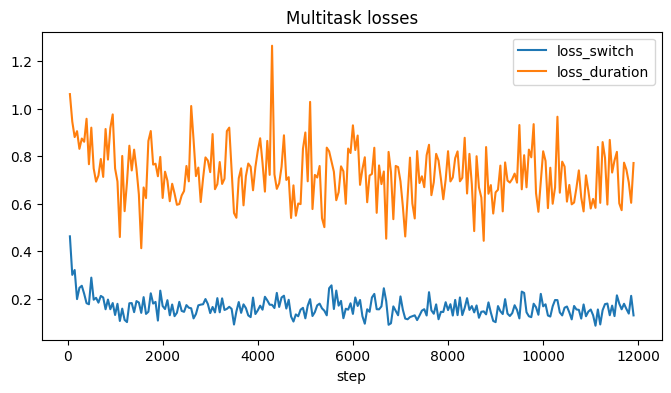

In [17]:
import matplotlib.pyplot as plt
log = pd.read_csv(f"{CFG.run_dir}/loss_log.csv")
log.plot(x="step", y=["loss_switch", "loss_duration"], figsize=(8, 4), title="Multitask losses")
plt.show()

In [23]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt


def _draw_cm(ax, cm, labels, title):
    """Colour = row-normalised % (i.e. recall per true class); text = % and raw count."""
    norm = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, f"{norm[i, j]:.0%}\n({cm[i, j]:,})", ha="center", va="center",
                    color="white" if norm[i, j] > 0.6 else "black", fontsize=8)
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, fontsize=8)
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=8)
    ax.set_xlabel("predicted", fontsize=8); ax.set_ylabel("true", fontsize=8)
    ax.set_title(title, fontsize=10)


def plot_confusions(run_dir, which="test@dev_thr", thr=None):
    pred = np.load(f"{run_dir}/test_predictions.npz")
    if thr is None:
        thr = json.load(open(f"{run_dir}/results.json"))[which]["threshold"]
    pair, y, p = pred["pair"], pred["y_sw"], pred["p_sw"]
    yd, dp = pred["y_dur"], pred["dur_pred"]
    yhat = (p >= thr).astype(int)
    groups = sorted(set(pair.tolist())) + ["ALL"]

    # 1) switch prediction (binary), per pair
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    rows = []
    for ax, g in zip(axes.flat, groups):
        m = np.ones_like(y, bool) if g == "ALL" else pair == g
        cm = confusion_matrix(y[m], yhat[m], labels=[0, 1])
        _draw_cm(ax, cm, ["no switch", "switch"], g)
        tn, fp, fn, tp = cm.ravel()
        rows.append({"pair": g, "TP": tp, "FP": fp, "FN": fn, "TN": tn,
                     "missed switches %": round(100 * fn / max(tp + fn, 1), 1),
                     "false alarms %": round(100 * fp / max(fp + tn, 1), 1)})
    for ax in axes.flat[len(groups):]:
        ax.axis("off")
    fig.suptitle(f"Switch prediction confusion matrices (threshold {thr:.2f})", fontsize=13)
    fig.tight_layout()
    fig.savefig(f"{run_dir}/confusion_switch.png", dpi=200, bbox_inches="tight")
    plt.show()
    display(pd.DataFrame(rows).set_index("pair"))

    # 2) duration prediction (3 classes), only at positions where a switch truly follows
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    for ax, g in zip(axes.flat, groups):
        m = (yd >= 0) & (np.ones_like(y, bool) if g == "ALL" else pair == g)
        cm = confusion_matrix(yd[m], dp[m], labels=[0, 1, 2])
        _draw_cm(ax, cm, ["small", "medium", "large"], g)
    for ax in axes.flat[len(groups):]:
        ax.axis("off")
    fig.suptitle("Duration prediction confusion matrices (at true switch positions)", fontsize=13)
    fig.tight_layout()
    fig.savefig(f"{run_dir}/confusion_duration.png", dpi=200, bbox_inches="tight")
    plt.show()
    print(f"saved: {run_dir}/confusion_switch.png and {run_dir}/confusion_duration.png")

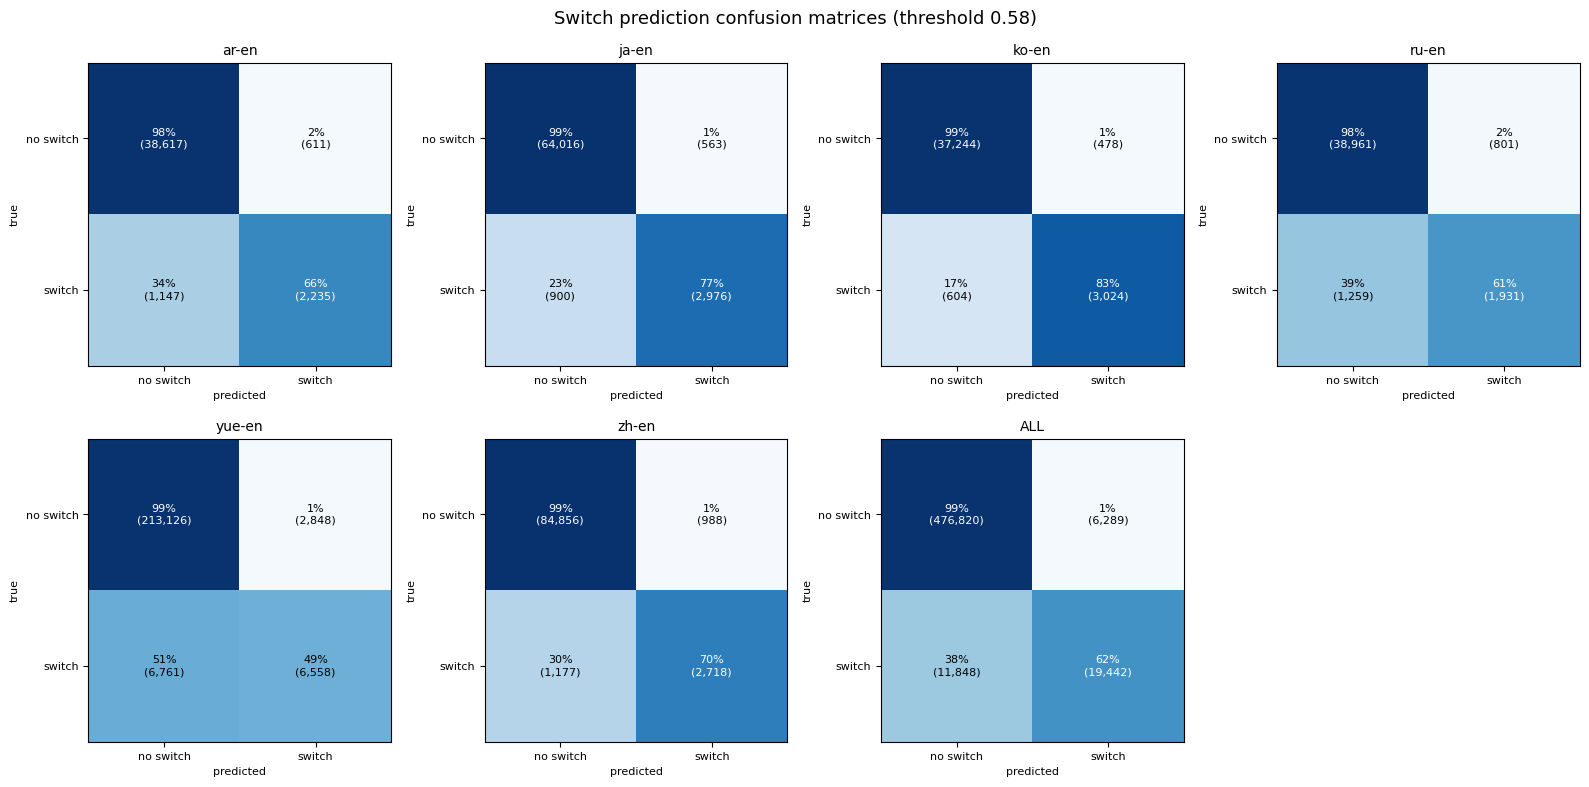

,TP,FP,FN,TN,missed switches %,false alarms %
pair,,,,,,
ar-en,2235,611,1147,38617,33.9,1.6
ja-en,2976,563,900,64016,23.2,0.9
ko-en,3024,478,604,37244,16.6,1.3
ru-en,1931,801,1259,38961,39.5,2.0
yue-en,6558,2848,6761,213126,50.8,1.3
zh-en,2718,988,1177,84856,30.2,1.2
ALL,19442,6289,11848,476820,37.9,1.3


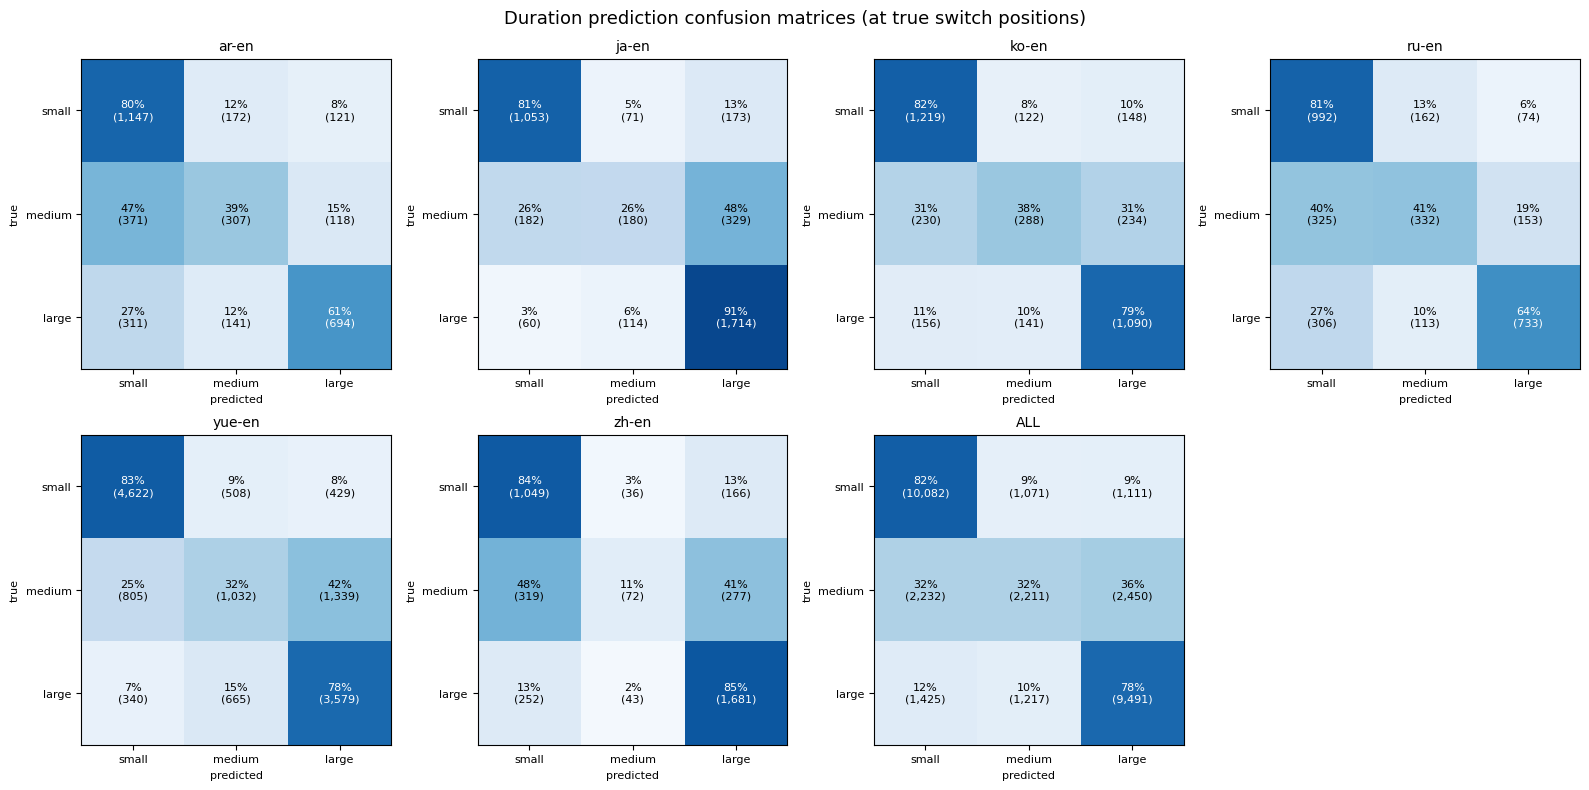

saved: /kaggle/working/cs_predict/runs/mbert/confusion_switch.png and /kaggle/working/cs_predict/runs/mbert/confusion_duration.png


In [24]:
plot_confusions(f"{PROJ}/runs/mbert")